<a href="https://colab.research.google.com/github/Angelavasconez/UCG-Paradigmas/blob/main/Explorador.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Dataset seleccionado

**Nombre del Dataset:** Watch Market Dataset

**Enlace directo de Kaggle:** https://www.kaggle.com/datasets/beridzeg45/watch-prices-dataset

**Descripción:**
Este conjunto de datos registra información detallada y comercial sobre el mercado global de relojes, abarcando desde modelos asequibles hasta piezas de alta relojería. Incluye características técnicas y de mercado como la marca (Brand), el modelo (Model), el tipo de movimiento (Movement), el material de la caja (Case Material), el año de lanzamiento (Year) y el precio en dólares (Price USD). Estas variables claves permiten perfilar la industria relojera, entender el valor de los materiales y evaluar cómo la mecánica influye en el costo final, siendo el precio la variable objetivo principal para estimaciones.

**Justificación**

EL dataset es ideal para la exploracion por su riqueza en variables mixtas: catgóricas (marcas, movimiento, material), numéricas continuas (precio) y temporales (año). Esta variedad permite agrupar y comparar el valor de mercado entre fabricantes suizos y japoneses. Para la inteligencia srtificial, rsulta muy útil para entrenar modelos de regresión que predigan el precio de un reloj en función de sus características físicas o modelos de clasificación para categorizar piezas en gamas de lujo frente a gamas de entrada.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from abc import ABC, abstractmethod

In [2]:
RUTA_DATASET = "/content/data/watches (cleaned).csv"  # Ajuste al nombre real del archivo descargado de Kaggle

if os.path.exists(RUTA_DATASET):
    df = pd.read_csv(RUTA_DATASET)
    print(f"Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas")
    display(df.head())
else:
    print("Verifique la ruta del archivo cargado en Colab.")

Dataset cargado: 45024 filas x 23 columnas


,Brand,Movement,Case material,Bracelet material,Year of production,Condition,Scope of delivery,Gender,Price,Availability,...,Crystal,Dial,Bracelet color,Clasp,Watches Sold by the Seller,Active listing of the seller,Fast Shipper,Trusted Seller,Punctuality,Seller Reviews
0,Alpina,Quartz,Steel,Rubber,NaN,New,"Original box, original papers",Men's watch/Unisex,895.0,Item is in stock,...,Sapphire crystal,Black,Black,Buckle,20.0,36.0,0,0,1,15.0
1,Lip,NaN,NaN,NaN,1973.0,Used (Good),"No original box, no original papers",Men's watch/Unisex,701.0,Item is in stock,...,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
2,Audemars Piguet,Automatic,Titanium,Titanium,2022.0,Used (Very good),"Original box, original papers",Men's watch/Unisex,39825.0,Item is in stock,...,Sapphire crystal,Grey,NaN,Fold clasp,2.0,48.0,0,1,1,4.0
3,Bulova,Automatic,NaN,NaN,1974.0,Used (Fair),"No original box, no original papers",Men's watch/Unisex,385.0,Item is in stock,...,NaN,Brown,NaN,NaN,NaN,NaN,0,0,0,NaN
4,Philip Watch,Automatic,Yellow gold,Leather,NaN,Like new & unworn,"No original box, no original papers",Men's watch/Unisex,1718.0,Item is in stock,...,NaN,Champagne,Brown,NaN,NaN,NaN,0,0,0,NaN


In [3]:
def perfil_calidad_datos(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Genera un perfil de calidad por variable del DataFrame.

    Parametros
    ----------
    dataframe : pd.DataFrame
        DataFrame a analizar.

    Retorna
    -------
    pd.DataFrame
        Perfil de calidad por variable.
    """

    # TODO: validar entrada
    if not isinstance(dataframe, pd.DataFrame):
      raise TypeError("Debe ingresar un DataFrame válido.")

    # TODO: calcular tipo, nulos, porcentaje de nulos y valores únicos
    perfil = pd.DataFrame({
      'Tipo de Dato': dataframe.dtypes,
      'Valores Nulos': dataframe.isnull().sum(),
      'Porcentaje Nulos (%)': (dataframe.isnull().sum() / len(dataframe)) * 100,
      'Valores Únicos': dataframe.nunique()
    })

    # TODO: incorporar o reportar duplicados
    duplicados = dataframe.duplicated().sum()
    print(f"Reporte: Se encontraron {duplicados} filas duplicadas en el dataset.")

    # TODO: retornar el perfil
    return perfil

# Validación para evitar NameError si el dataset aún no ha sido cargado exitosamente
if 'df' in globals():
    perfil = perfil_calidad_datos(df)
    display(perfil)
else:
    print("La variable 'df' no está definida. Por favor, asegúrese de cargar el dataset correctamente en la sección 2.")

Reporte: Se encontraron 1575 filas duplicadas en el dataset.


,Tipo de Dato,Valores Nulos,Porcentaje Nulos (%),Valores Únicos
Brand,object,1294,2.874023,479
Movement,object,3839,8.526564,5
Case material,object,6707,14.896500,20
Bracelet material,object,7817,17.361851,26
Year of production,float64,19293,42.850480,146
Condition,object,2052,4.557569,7
Scope of delivery,object,1294,2.874023,4
Gender,object,5817,12.919776,2
Price,float64,2273,5.048419,9058
Availability,object,1556,3.455935,3


In [4]:
def resumir_variable(dataframe: pd.DataFrame, columna: str):
    """Resume una variable según su naturaleza numérica o categórica.

    Parametros
    ----------
    dataframe : pd.DataFrame
        DataFrame a analizar.
    columna : str
        Nombre de la columna a resumir.

    Retorna
    -------
    pd.DataFrame
        Resumen de la variable.
    """

    # TODO: validar columna
    if columna not in dataframe.columns:
      raise ValueError(f"La columna '{columna}' no existe en el DataFrame.")

    # TODO: identificar tipo
    if pd.api.types.is_numeric_dtype(dataframe[columna]):
      resumen = dataframe[columna].describe(percentiles=[.25, .50, .75]).to_frame()
      resumen.columns = [f'Estadísticos - {columna}']
      return resumen
    else:
      frecuencias = dataframe[columna].value_counts()
      proporciones = dataframe[columna].value_counts(normalize=True) * 100
      resumen = pd.DataFrame({
        'Frecuencia': frecuencias,
        'Proporción (%)': proporciones
      })
      return resumen

resumen_variable = resumir_variable(df, "Price")
display(resumen_variable)

,Estadísticos - Price
count,4.275100e+04
mean,1.013547e+04
std,5.743702e+04
min,1.000000e+00
25%,6.000000e+02
50%,1.783000e+03
75%,5.314000e+03
max,5.999995e+06


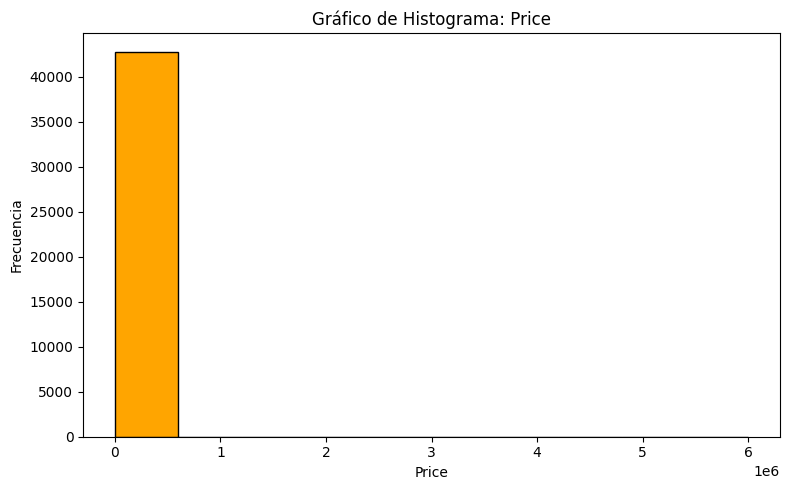

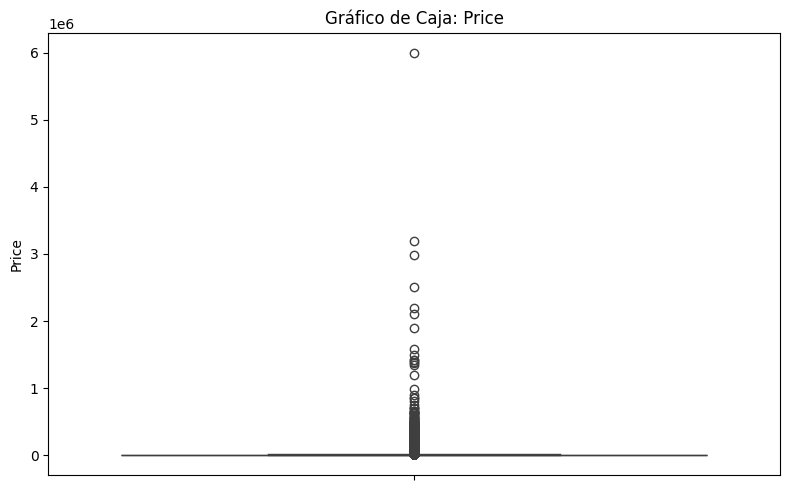

In [5]:
def visualizar_datos(dataframe: pd.DataFrame, tipo: str, x: str,
    y: str | None = None, libreria: str = "plotly"):

    """
    Construye una visualización según tipo, variables y librería seleccionada.

    Parametros
    ----------
    dataframe : pd.DataFrame
        DataFrame a analizar.
    tipo : str
        Tipo de gráfico a construir.
    x : str
        Variable principal.
    y : str | None
        Variable secundaria.
    libreria : str
        Librería de visualización.
    """
    tipos_validos = {"histograma", "caja", "dispersion", "barras"}
    librerias_validas = {"matplotlib", "seaborn", "plotly"}

    # TODO: validar columnas, tipo y librería
    if x not in dataframe.columns:
      raise ValueError(f"La columna '{x}' no existe en el DataFrame.")
    if y is not None and y not in dataframe.columns:
      raise ValueError(f"La columna '{y}' no existe en el DataFrame.")

    if tipo not in tipos_validos:
      raise ValueError(f"Tipo de gráfico inválido. Elija entre: {tipos_validos}")
    if libreria not in librerias_validas:
      raise ValueError(f"Librería inválida. Elija entre: {librerias_validas}")

    # TODO: construir título
    titulo = f"Gráfico de {tipo.capitalize()}: {x}" + (f" vs. {y}" if y else "")

    # TODO: implementar las ramas de visualización
    if libreria == "matplotlib":
      plt.figure(figsize=(8, 5))
      if tipo == "histograma":
        plt.hist(dataframe[x].dropna(), bins=10, color='orange', edgecolor='black')
        plt.ylabel("Frecuencia")
      elif tipo == "caja":
        plt.boxplot(dataframe[x].dropna(), vert=True)
        plt.ylabel(x)
      elif tipo == "dispersion":
        plt.scatter(dataframe[x], dataframe[y], alpha=0.7)
        plt.ylabel(y)
      elif tipo == "barras":
        conteo = dataframe[x].value_counts()
        plt.bar(conteo.index.astype(str), conteo.values, color='coral')
        plt.ylabel("Cantidad")
        plt.xticks(rotation=45)
      plt.title(titulo)
      plt.xlabel(x)
      plt.tight_layout()
      plt.show()

    elif libreria == "seaborn":
      plt.figure(figsize=(8, 5))
      if tipo == "histograma": sns.histplot(data=dataframe, x=x, kde=True, color='purple')
      elif tipo == "caja": sns.boxplot(data=dataframe, x=y, y=x) if y else sns.boxplot(data=dataframe, y=x)
      elif tipo == "dispersion": sns.scatterplot(data=dataframe, x=x, y=y)
      elif tipo == "barras":
        sns.countplot(data=dataframe, x=x, palette="viridis")
        plt.ylabel("Cantidad")
        plt.xticks(rotation=45)
      plt.title(titulo)
      plt.tight_layout()
      plt.show()

    elif libreria == "plotly":
      if tipo == "histograma":
        fig = px.histogram(dataframe, x=x, title=titulo)
      elif tipo == "caja":
        fig = px.box(dataframe, x=y, y=x, title=titulo) if y else px.box(dataframe, y=x, title=titulo)
      elif tipo == "dispersion": fig = px.scatter(dataframe, x=x, y=y, title=titulo)
      elif tipo == "barras":
        conteo = dataframe[x].value_counts().reset_index()
        conteo.columns = [x, 'count']
        fig = px.bar(conteo, x=x, y='count', title=titulo)
      fig.show()

visualizar_datos(df, tipo="histograma", x="Price", libreria="matplotlib")
visualizar_datos(df, tipo="caja", x="Price", libreria="seaborn")
visualizar_datos(df, tipo="dispersion", x="Price", y="Movement", libreria="plotly")


In [6]:
def comparar_segmentos(
    dataframe: pd.DataFrame, grupo: str, metrica: str, operacion: str = "media"
) -> pd.DataFrame:
    """
    Compara segmentos mediante una operación de agregación seleccionable.

    Parametros
    ----------
    dataframe : pd.DataFrame
        DataFrame a analizar.
    grupo : str
        Variable categórica para agrupar.
    metrica : str
        Variable numérica para operar.
    operacion : str

    Retorna
    -------
    pd.DataFrame
        Resumen de la operación.
    """
    # TODO: validar columnas y operación
    if grupo not in dataframe.columns or metrica not in dataframe.columns:
      raise ValueError("Las columnas de 'grupo' y 'metrica' deben existir en el DataFrame.")

    if operacion not in ["media", "mediana", "conteo", "suma"]:
      raise ValueError("La operación debe ser 'media', 'mediana', 'conteo' o 'suma'.")

    # TODO: agrupar y calcular la métrica
    if operacion == "media":
      resumen = dataframe.groupby(grupo)[metrica].mean()
    elif operacion == "mediana":
      resumen = dataframe.groupby(grupo)[metrica].median()
    elif operacion == "conteo":
      resumen = dataframe.groupby(grupo)[metrica].count()
    elif operacion == "suma":
      resumen = dataframe.groupby(grupo)[metrica].sum()

    resumen = resumen.sort_values(ascending=False)
    return resumen.to_frame()

resumen = comparar_segmentos(df, "Brand", "Price", "media")
display(resumen)

,Price
Brand,
Richard Mille,328157.029126
Greubel Forsey,318152.363636
Patek Philippe,169249.471831
F.P.Journe,141143.735294
Christophe Claret,108237.576923
...,...
Skagen,94.789474
Lorus,94.731959
Gant,71.666667


In [7]:
def ejecutar_explorador(dataframe: pd.DataFrame, configuracion: dict):
    """
    Coordina el perfil, resumen, comparación y visualización definidos previamente.

    Parametros
    ----------
    dataframe : pd.DataFrame
        DataFrame a analizar.
    configuracion : dict
        Diccionario con parámetros de configuración.

    Retorna
    -------
    dict
        Diccionario con resultados.
    """

    print("---INCIANDO EXPLORADOR FUNCIONAL ---\n")

    #1. Llamar a Función 1: Perfil de calidad
    print("1. PERFIL DE CALIDAD DE DATOS")
    perfil = perfil_calidad_datos(dataframe)
    print(perfil)
    print("-" * 50)

    #2. Llamar a Función 2: Resumen inteligente
    print("2. RESUMEN DE VARIABLES")
    resumen_variable = resumir_variable(dataframe, configuracion["variable_resumen"])
    print(resumen_variable)
    print("-" * 50)

    #3. Llamar a Función 3: Visualizar Datos
    print("3. VISUALIZACIÓN DE DATOS")
    visualizar_datos(dataframe, configuracion["grafico"]["tipo"], configuracion["grafico"]["x"],
      configuracion["grafico"]["y"], configuracion["grafico"]["libreria"])
    print("-" * 50)

    #4. Llamar a Función 4: Comparar Segmentos
    print("4. COMPARACIÓN DE SEGMENTOS")
    resumen = comparar_segmentos(dataframe, configuracion["grupo"], configuracion["metrica"], configuracion["operacion"])
    print(resumen)
    print("-" * 50)

    # TODO: devolver una estructura con los resultados principales
    resultados = {
      "perfil": perfil,
      "resumen_variable": resumen_variable,
      "resumen": resumen
    }
    return resultados

configuracion = {
    "variable_resumen": "Price",
    "grupo": "Movement",
    "metrica": "Price",
    "operacion": "media",
    "grafico": {
        "tipo": "histograma",
        "x": "Price",
        "y": "Movement",
        "libreria": "plotly"
    }
}
resultados = ejecutar_explorador(df, configuracion)

---INCIANDO EXPLORADOR FUNCIONAL ---

1. PERFIL DE CALIDAD DE DATOS
Reporte: Se encontraron 1575 filas duplicadas en el dataset.
                             Tipo de Dato  Valores Nulos  \
Brand                              object           1294   
Movement                           object           3839   
Case material                      object           6707   
Bracelet material                  object           7817   
Year of production                float64          19293   
Condition                          object           2052   
Scope of delivery                  object           1294   
Gender                             object           5817   
Price                             float64           2273   
Availability                       object           1556   
Shape                              object           6327   
Face Area                         float64           6381   
Water resistance                  float64          23171   
Crystal                        

--------------------------------------------------
4. COMPARACIÓN DE SEGMENTOS
                       Price
Movement                    
Manual winding  18188.951493
Automatic       11363.589425
Quartz           1855.023412
Smartwatch        899.810811
Solar             808.037383
--------------------------------------------------
